# Chapitre 3 - Cours 4 : Classer des modèles par comparaisons (Elo, Bradley-Terry)

Ce dernier notebook de cours couvre la section *Ranking Models with Comparative
Evaluation* : évaluation ponctuelle contre comparative, algorithmes de classement (Elo,
Bradley-Terry), et les trois difficultés que le livre détaille dans *Challenges of
Comparative Evaluation* (passage à l'échelle et transitivité, standardisation et contrôle
qualité, passage du relatif à l'absolu), avant *The Future of Comparative Evaluation*.
Tout est simulé en numpy : aucune donnée réelle d'arène n'est nécessaire pour comprendre
les mécanismes.

**Plan.**

1. Évaluation ponctuelle ou comparative, et l'architecture d'une arène.
2. Le modèle de Bradley-Terry et la formule d'Elo.
3. Elo en pratique : trajectoires, facteur K, sensibilité à l'ordre des matchs.
4. Bradley-Terry par maximum de vraisemblance (algorithme MM) et intervalles bootstrap.
5. La table 3-6 du livre : classement et intransitivité.
6. Quand la transitivité casse : simulation pierre-feuille-ciseaux.
7. Combien de comparaisons faut-il ? Croissance quadratique et appariement adaptatif.
8. Du comparatif à l'absolu : que signifie un taux de victoire de 51 % ?

In [1]:
import math
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import kendalltau

from aie import ch03_evaluation as ev
from aie.diagrams import Diagram
from aie.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                          annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
rng = np.random.default_rng(0)
pd.set_option("display.precision", 3)

## 1. Évaluation ponctuelle ou comparative (section *Ranking Models with Comparative Evaluation*)

Souvent, on évalue des modèles non pour leur score mais pour savoir **lequel choisir** :
on veut un classement. Deux voies :

- **ponctuelle** (« pointwise ») : chaque modèle est noté séparément (benchmark, échelle
  de Likert), puis on trie les notes ;
- **comparative** : on présente des réponses côte à côte et l'on demande laquelle est
  meilleure ; un algorithme transforme ces duels en classement.

Pour des qualités subjectives, comparer est plus facile que noter (dire laquelle de deux
chansons on préfère est plus simple que donner une note à chacune). C'est le principe de
Chatbot Arena (LMSYS) : un utilisateur écrit un prompt, reçoit les réponses de deux
modèles anonymes, vote, et les noms ne sont révélés qu'après. À ne pas confondre avec un
test A/B, où chaque utilisateur ne voit qu'une seule variante.

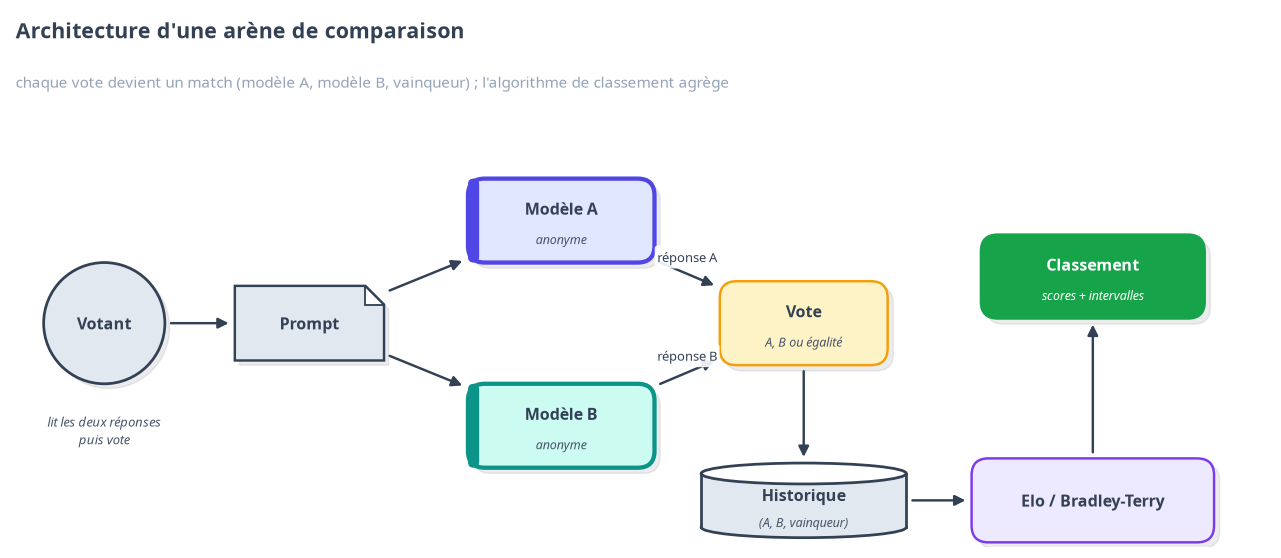

In [2]:
d = Diagram(13.5, 4.8, title="Architecture d'une arène de comparaison",
            subtitle="chaque vote devient un match (modèle A, modèle B, vainqueur) ; l'algorithme de classement agrège")
d.box("u", 1.0, 2.4, "Votant", color=SLATE, kind="user", w=1.3)
d.box("p", 3.2, 2.4, "Prompt", color=SLATE, kind="doc", w=1.6, h=0.8)
d.box("ma", 5.9, 3.5, "Modèle A", sub="anonyme", color=INDIGO, kind="model", w=2.0)
d.box("mb", 5.9, 1.3, "Modèle B", sub="anonyme", color=TEAL, kind="model", w=2.0)
d.box("v", 8.5, 2.4, "Vote", sub="A, B ou égalité", color=AMBER, w=1.8)
d.box("log", 8.5, 0.5, "Historique", sub="(A, B, vainqueur)", color=SLATE, kind="db", w=2.2, h=0.8)
d.box("algo", 11.6, 0.5, "Elo / Bradley-Terry", color=VIOLET, w=2.6)
d.box("lb", 11.6, 2.9, "Classement", sub="scores + intervalles", color=GREEN, w=2.4, filled=True)
d.arrow("u", "p"); d.arrow("p", "ma"); d.arrow("p", "mb")
d.arrow("ma", "v", "réponse A"); d.arrow("mb", "v", "réponse B")
d.note(1.0, 1.25, "lit les deux réponses\npuis vote", fontsize=8.5)
d.arrow("v", "log"); d.arrow("log", "algo"); d.arrow("algo", "lb")
d.show()

Le livre insiste sur une mise en garde : **toutes les questions ne relèvent pas de la
préférence**. « Y a-t-il un lien entre ondes des téléphones et tumeurs ? » relève de la
justesse, pas d'un vote ; et un utilisateur qui pose une question de maths dont il ignore
la réponse ne sait pas choisir entre deux réponses. Le vote par préférence fonctionne
quand les votants maîtrisent le sujet.

> **À retenir.** L'évaluation comparative remplace la note absolue par des duels,
> plus faciles à juger pour des qualités subjectives. Un algorithme de classement
> transforme l'historique des duels en scores.

## 2. Le modèle de Bradley-Terry et la formule d'Elo

**Modèle de Bradley-Terry (1952).** Chaque modèle $i$ a une force $s_i$ et
$$P(i \text{ bat } j) = \frac{e^{s_i}}{e^{s_i} + e^{s_j}} = \sigma(s_i - s_j),$$
où $\sigma$ est la fonction logistique. Seules les **différences** de forces comptent.

**Elo** (échecs, années 1960) utilise la même forme avec une autre unité :
$$E_A = P(A \text{ bat } B) = \frac{1}{1 + 10^{(R_B - R_A)/400}}.$$
Avec $s = R \ln 10 / 400$, c'est exactement Bradley-Terry : 400 points d'écart
correspondent à une cote de 10 contre 1 (probabilité $10/11 \approx 91\,\%$).

**La mise à jour d'Elo est une descente de gradient stochastique.** Après un match de
résultat $S \in \{0, \tfrac12, 1\}$, Elo fait $R_A \leftarrow R_A + K(S - E_A)$. Or la
log-vraisemblance du résultat, $\ell = S\log E_A + (1-S)\log(1-E_A)$, a pour dérivée
$\partial \ell / \partial R_A = (S - E_A)\ln 10/400$. La règle d'Elo est donc un pas de
gradient de taille $\eta = 400K/\ln 10$ sur **un seul match** : un apprentissage en
ligne à pas constant. Deux conséquences, que l'on va observer : le résultat dépend de
l'**ordre** des matchs, et les scores ne convergent jamais vraiment (ils fluctuent avec
une amplitude liée à $K$). Elo conserve aussi la somme des scores (ce que gagne A, B le
perd).

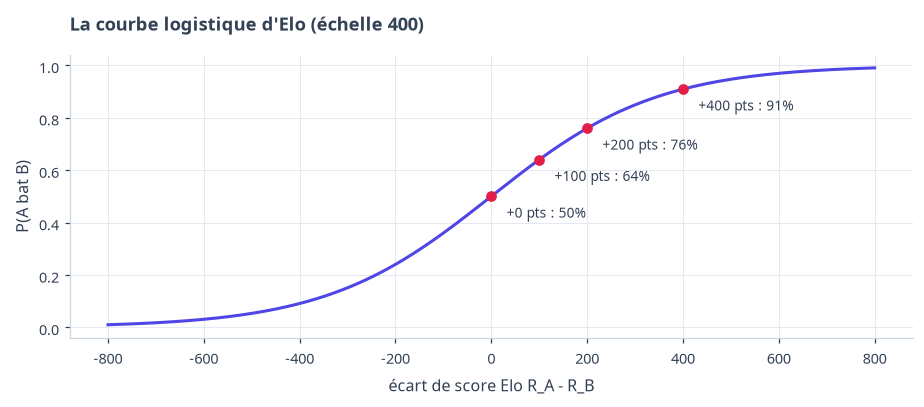

In [3]:
diff = np.linspace(-800, 800, 400)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.plot(diff, [ev.elo_expected(x, 0) for x in diff], color=INDIGO)
for x in [0, 100, 200, 400]:
    p = ev.elo_expected(x, 0)
    ax.scatter([x], [p], color=ROSE, zorder=3)
    ax.annotate(f"+{x} pts : {p:.0%}", (x, p), (10, -14), textcoords="offset points", fontsize=9)
ax.set_xlabel("écart de score Elo R_A - R_B"); ax.set_ylabel("P(A bat B)")
ax.set_title("La courbe logistique d'Elo (échelle 400)")
plt.tight_layout(); plt.show()

> **À retenir.** Elo et Bradley-Terry reposent sur le même modèle logistique des
> différences de forces. Bradley-Terry estime les forces par maximum de vraisemblance sur
> tous les matchs ; Elo les met à jour match après match, comme un gradient stochastique.

## 3. Elo en pratique : trajectoires, facteur K et sensibilité à l'ordre

Simulons cinq modèles de forces connues (en points Elo : 1 250, 1 150, 1 120, 1 000, 900 ;
les modèles 2 et 3 sont proches) et 3 000 matchs entre paires tirées au hasard.

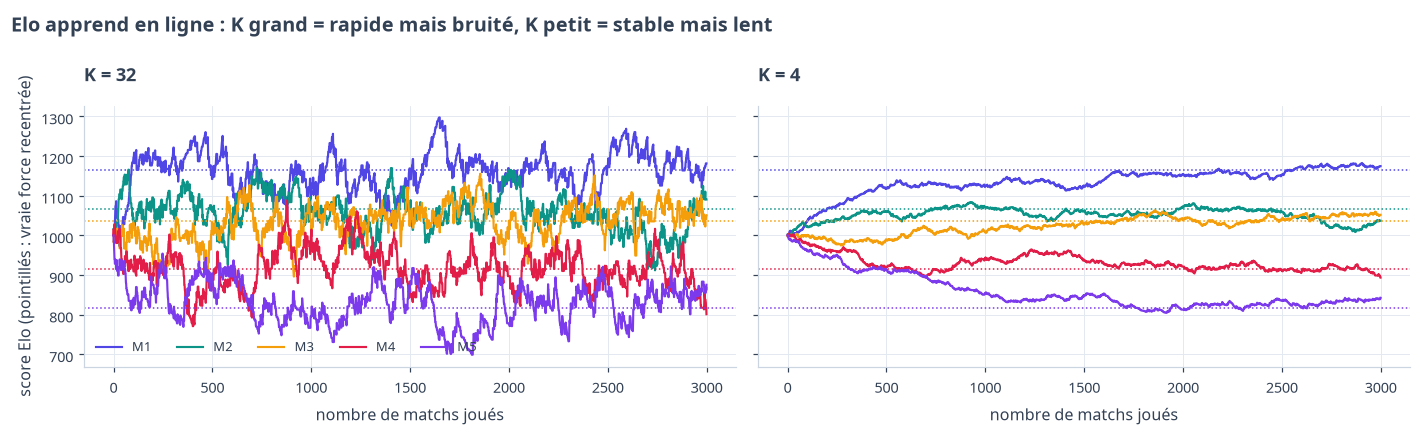

In [4]:
vrai = np.array([1250, 1150, 1120, 1000, 900.0])
noms = [f"M{i + 1}" for i in range(5)]
P = ev.prob_matrix_from_elo(vrai)
matchs = ev.simulate_matches(P, 3000, np.random.default_rng(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, K in zip(axes, [32, 4]):
    _, hist = ev.elo_ratings(matchs, 5, k=K, history=True)
    for i in range(5):
        ax.plot(hist[:, i], color=COLORS[i], lw=1.4, label=noms[i])
        ax.axhline(vrai[i] - vrai.mean() + 1000, color=COLORS[i], ls=":", lw=1)
    ax.set_title(f"K = {K}")
    ax.set_xlabel("nombre de matchs joués")
axes[0].set_ylabel("score Elo (pointillés : vraie force recentrée)")
axes[0].legend(ncol=5, loc="lower left", fontsize=8.5)
finish(fig, "Elo apprend en ligne : K grand = rapide mais bruité, K petit = stable mais lent")
plt.show()

Avec $K = 32$, les scores atteignent vite le bon ordre de grandeur mais oscillent en
permanence (M2 et M3 échangent régulièrement leurs places) ; avec $K = 4$, ils sont plus
stables mais mettent des centaines de matchs à converger. **Sensibilité à l'ordre** :
rejouons exactement les mêmes 3 000 matchs dans 200 ordres aléatoires différents.

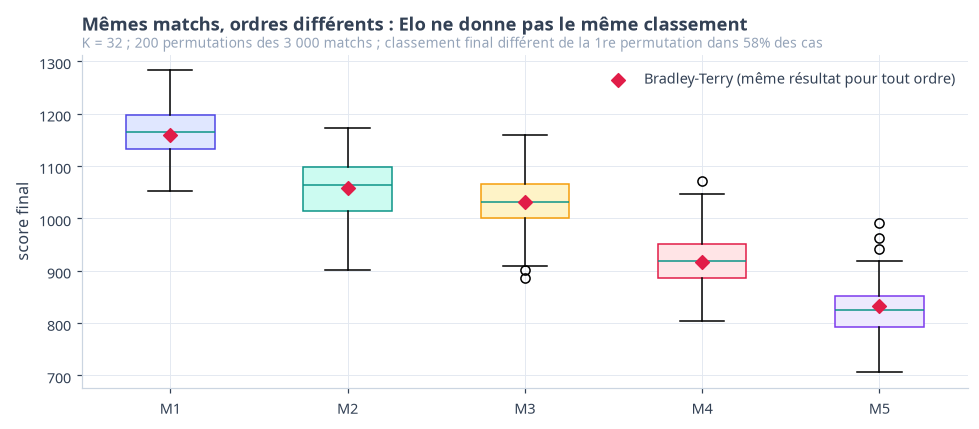

In [5]:
finals = np.array([ev.elo_ratings([matchs[i] for i in np.random.default_rng(s).permutation(len(matchs))], 5, k=32)
                   for s in range(200)])
bt_elo = ev.bt_to_elo(ev.bradley_terry(ev.win_matrix(matchs, 5)))
rang_change = np.mean([np.argsort(-f).tolist() != np.argsort(-finals[0]).tolist() for f in finals])
fig, ax = plt.subplots(figsize=(9, 4))
bp = ax.boxplot([finals[:, i] for i in range(5)], tick_labels=noms, patch_artist=True, widths=0.5)
for patch, c in zip(bp["boxes"], COLORS):
    patch.set_facecolor(LIGHT[c]); patch.set_edgecolor(c)
ax.scatter(range(1, 6), bt_elo, marker="D", color=ROSE, zorder=4, s=40, label="Bradley-Terry (même résultat pour tout ordre)")
ax.set_ylabel("score final")
ax.set_title("Mêmes matchs, ordres différents : Elo ne donne pas le même classement")
subtitle(ax, f"K = 32 ; 200 permutations des 3 000 matchs ; classement final différent de la 1re permutation "
             f"dans {rang_change:.0%} des cas")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

Les **mêmes** données produisent des scores Elo différents selon l'ordre de traitement,
au point d'inverser M2 et M3 dans une part notable des cas. C'est précisément la raison
invoquée par LMSYS pour abandonner Elo au profit de Bradley-Terry (sensibilité à l'ordre
des évaluateurs et des prompts). Elo reste pertinent quand les forces **évoluent** dans
le temps (un joueur d'échecs progresse) ; un modèle figé n'évolue pas, et l'on préfère
une estimation globale.

> **À retenir.** Elo est un estimateur en ligne : son résultat dépend de l'ordre des
> matchs et du facteur K. Pour des modèles figés, l'estimation par maximum de
> vraisemblance (Bradley-Terry) est plus adaptée.

## 4. Bradley-Terry par maximum de vraisemblance

Avec $w_{ij}$ le nombre de victoires de $i$ sur $j$ et $\pi_i = e^{s_i}$, la
log-vraisemblance est
$$\ell(\pi) = \sum_{i \ne j} w_{ij}\big[\log \pi_i - \log(\pi_i + \pi_j)\big].$$
Elle est concave en $s = \log \pi$ et ne dépend que des différences (on fixe la moyenne
des $s_i$ à 0). **Algorithme MM** (Hunter, 2004) : en minorant $-\log(\pi_i+\pi_j)$ par
sa tangente au point courant, on obtient une fonction facile à maximiser, d'où
l'itération
$$\pi_i \leftarrow \frac{W_i}{\sum_{j \ne i} \dfrac{n_{ij}}{\pi_i + \pi_j}}, \qquad W_i = \sum_j w_{ij},\; n_{ij} = w_{ij} + w_{ji},$$
qui augmente la vraisemblance à chaque pas (implémentée dans `ev.bradley_terry`). À
l'optimum, chaque modèle a exactement autant de victoires **attendues** que de victoires
**observées**. Le résultat ne dépend que de la matrice des victoires, pas de l'ordre.

On quantifie l'incertitude par **bootstrap** : on rééchantillonne les matchs avec remise,
on réestime, et l'on prend les quantiles 2,5 % et 97,5 %, comme les classements publics.
Comparons les intervalles obtenus avec 300 et 3 000 matchs.

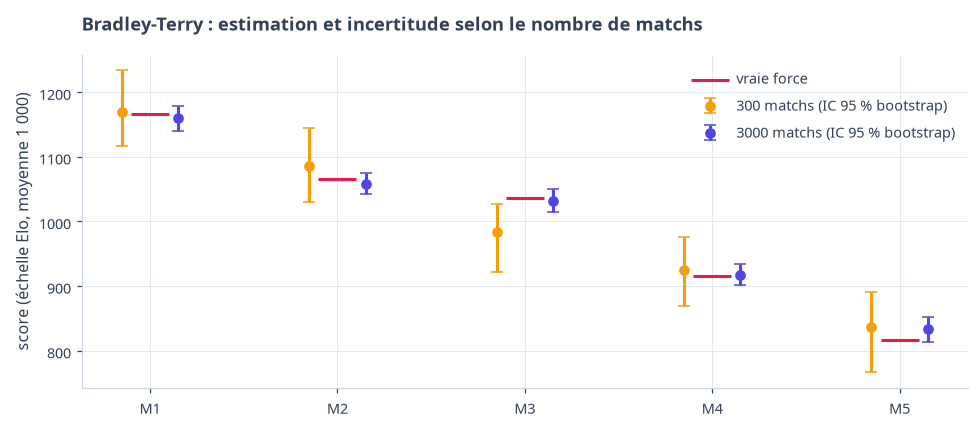

In [6]:
def bootstrap_bt(matchs, n_models, B=200, seed=0):
    r = np.random.default_rng(seed)
    m = np.array(matchs)
    out = []
    for _ in range(B):
        idx = r.integers(len(m), size=len(m))
        w = ev.win_matrix([(int(a), int(b), s) for a, b, s in m[idx]], n_models)
        out.append(ev.bt_to_elo(ev.bradley_terry(w, prior=0.5)))
    return np.array(out)


fig, ax = plt.subplots(figsize=(9, 4))
for k, (n, c) in enumerate([(300, AMBER), (3000, INDIGO)]):
    bs = bootstrap_bt(matchs[:n], 5)
    est = ev.bt_to_elo(ev.bradley_terry(ev.win_matrix(matchs[:n], 5), prior=0.5))
    lo, hi = np.percentile(bs, [2.5, 97.5], axis=0)
    x = np.arange(5) + (k - 0.5) * 0.3
    ax.errorbar(x, est, yerr=[est - lo, hi - est], fmt="o", color=c, capsize=4, label=f"{n} matchs (IC 95 % bootstrap)")
ax.scatter(np.arange(5), vrai - vrai.mean() + 1000, marker="_", s=600, color=ROSE, label="vraie force", zorder=4)
ax.set_xticks(range(5)); ax.set_xticklabels(noms); ax.set_ylabel("score (échelle Elo, moyenne 1 000)")
ax.set_title("Bradley-Terry : estimation et incertitude selon le nombre de matchs")
ax.legend()
plt.tight_layout(); plt.show()

Avec 300 matchs, les intervalles de M2 et M3 se chevauchent largement : impossible de
les départager honnêtement. Avec dix fois plus de matchs, les intervalles se resserrent
d'un facteur d'environ $\sqrt{10} \approx 3$. Un classement sans intervalles de confiance
donne une illusion de précision.

*Note sur l'échelle.* Le livre signale que Chatbot Arena, après être passé à
Bradley-Terry, a continué à afficher des « scores Elo » : les forces sont mises à
l'échelle Elo (multipliées par $400/\ln 10$ dans notre convention, plus 1 000), puis
décalées pour qu'un modèle de référence ait un score fixé. Seules les différences ont un
sens.

> **À retenir.** Bradley-Terry maximise la vraisemblance de tous les matchs à la fois :
> estimation indépendante de l'ordre, convergence garantie (MM), et incertitude
> quantifiable par bootstrap.

## 5. La table 3-6 du livre : classement et intransitivité (section *Ranking Models with Comparative Evaluation*)

Le livre donne les taux de victoire de cinq modèles (1 000 matchs par paire) et observe
qu'il n'est pas évident de les classer. Ajustons Bradley-Terry, puis comparons les taux
**prédits** par le modèle aux taux **observés**.

In [7]:
W = ev.book_win_matrix()
s_book = ev.bradley_terry(W)
elo_book = ev.bt_to_elo(s_book)
classement = pd.DataFrame({"score (échelle Elo)": elo_book, "victoires totales": W.sum(1)},
                          index=[f"Modèle {i}" for i in range(1, 6)]).sort_values("score (échelle Elo)", ascending=False)
classement["rang"] = range(1, 6)
rows = []
for a, b, p in ev.BOOK_WIN_RATES:
    rows.append(dict(paire=f"{a} vs {b}", observe=p, predit=ev.bt_prob(s_book[a - 1], s_book[b - 1])))
cmp_ = pd.DataFrame(rows)
cmp_["ecart"] = cmp_.predit - cmp_.observe
classement

,score (échelle Elo),victoires totales,rang
Modèle 5,1119.501,2800.0,1
Modèle 2,1043.054,2300.0,2
Modèle 3,970.344,1800.0,3
Modèle 1,933.550,1550.0,4
Modèle 4,933.550,1550.0,5


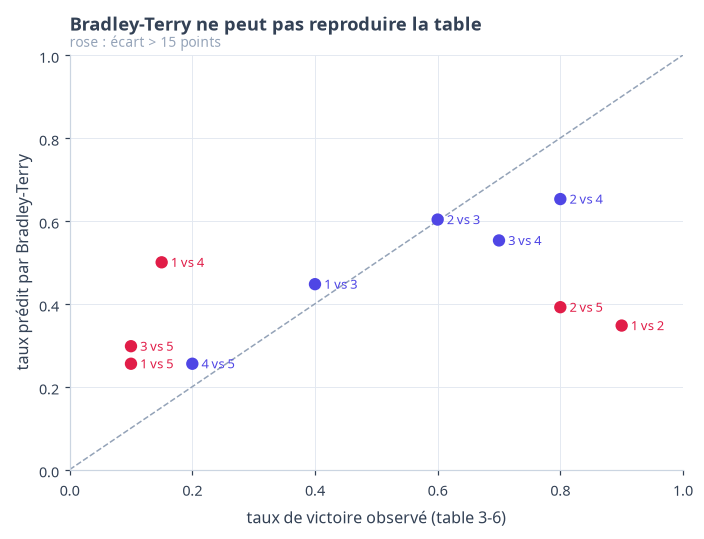

Triplets intransitifs (i bat j, j bat k, k bat i) : [(1, 2, 3), (1, 2, 4), (1, 2, 5)]


In [8]:
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot([0, 1], [0, 1], color=GRAY, ls="--", lw=1)
cols = [ROSE if abs(e) > 0.15 else INDIGO for e in cmp_.ecart]
ax.scatter(cmp_.observe, cmp_.predit, color=cols, s=50, zorder=3)
for r, c in zip(cmp_.itertuples(), cols):
    ax.annotate(r.paire, (r.observe, r.predit), (6, -3), textcoords="offset points", fontsize=8.5, color=c)
ax.set_xlabel("taux de victoire observé (table 3-6)"); ax.set_ylabel("taux prédit par Bradley-Terry")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_title("Bradley-Terry ne peut pas reproduire la table")
subtitle(ax, "rose : écart > 15 points")
plt.tight_layout(); plt.show()
print("Triplets intransitifs (i bat j, j bat k, k bat i) :",
      [tuple(int(x) + 1 for x in c) for c in ev.find_cycles3(W / (W + W.T + np.eye(5)))])

La table contient même trois **cycles**, qui passent tous par le duel 1 contre 2 : le
modèle 1 écrase le 2 (90 %), mais le 2 bat les modèles 3, 4 et 5, qui battent tous le
1 (par exemple 1 > 2 > 3 > 1). Aucun classement linéaire, donc aucun jeu de forces
Bradley-Terry, ne peut reproduire un cycle : le modèle fait au mieux (il classe 5
premier, 2 deuxième, et 1 ex aequo avec 4) et commet de grosses erreurs sur certaines
paires, à commencer par 1 contre 2. Le graphe des duels rend les cycles visibles (une
flèche va du vainqueur au perdant).

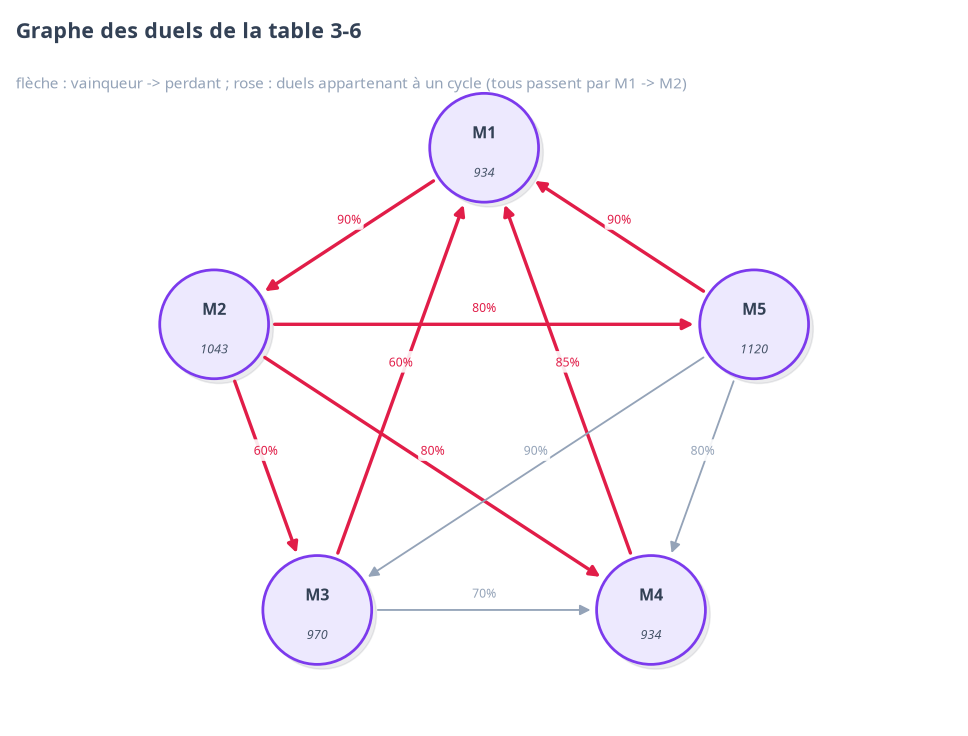

In [9]:
ang = np.pi / 2 + 2 * np.pi * np.arange(5) / 5
pos = {i: (5.0 + 3.0 * np.cos(a), 3.4 + 2.7 * np.sin(a)) for i, a in enumerate(ang)}
cyc = {(c[k], c[(k + 1) % 3]) for c in ev.find_cycles3(W / (W + W.T + np.eye(5))) for k in range(3)}
d = Diagram(10, 6.6, title="Graphe des duels de la table 3-6",
            subtitle="flèche : vainqueur -> perdant ; rose : duels appartenant à un cycle (tous passent par M1 -> M2)")
for i in range(5):
    d.box(f"m{i}", *pos[i], f"M{i + 1}", sub=f"{elo_book[i]:.0f}", color=VIOLET, kind="circle", w=1.15)
for a, b, p in ev.BOOK_WIN_RATES:
    gagnant, perdant, taux = (a - 1, b - 1, p) if p > 0.5 else (b - 1, a - 1, 1 - p)
    rouge = (gagnant, perdant) in cyc
    d.arrow(f"m{gagnant}", f"m{perdant}", f"{taux:.0%}", color=ROSE if rouge else GRAY, lw=2.2 if rouge else 1.2,
            label_pos=0.5, fontsize=8)
d.show()

Le livre rappelle que les algorithmes de classement **supposent la transitivité**, et
que plusieurs travaux (Boubdir et al., Balduzzi et al., Munos et al.) la mettent en
doute pour les modèles d'IA : les préférences humaines ne sont pas forcément
transitives, et des paires différentes sont jugées par des évaluateurs différents sur des
prompts différents. Le livre définit aussi ce qu'est un **bon classement** : un
classement qui **prédit** bien les matchs futurs (le mieux classé gagne plus d'une fois
sur deux). Mesurons-le sur la table.

In [10]:
acc = np.mean([(s_book[a - 1] > s_book[b - 1]) == (p > 0.5) for a, b, p in ev.BOOK_WIN_RATES])
print(f"Paires dont le favori selon Bradley-Terry est bien le vainqueur majoritaire : {acc:.0%}")

Paires dont le favori selon Bradley-Terry est bien le vainqueur majoritaire : 80%


> **À retenir.** Un classement linéaire suppose la transitivité. Quand les préférences
> forment des cycles, aucun score ne peut tout expliquer : il faut regarder les écarts
> entre taux prédits et observés, qui signalent les paires mal représentées.

## 6. Quand la transitivité casse : simulation pierre-feuille-ciseaux

Construisons un cas extrême : trois modèles P, F, C forment un cycle parfait (chacun bat
le suivant 75 % du temps), et deux modèles « normaux » (fort et faible) ont des
préférences transitives. Simulons 5 000 matchs et ajustons Bradley-Terry.

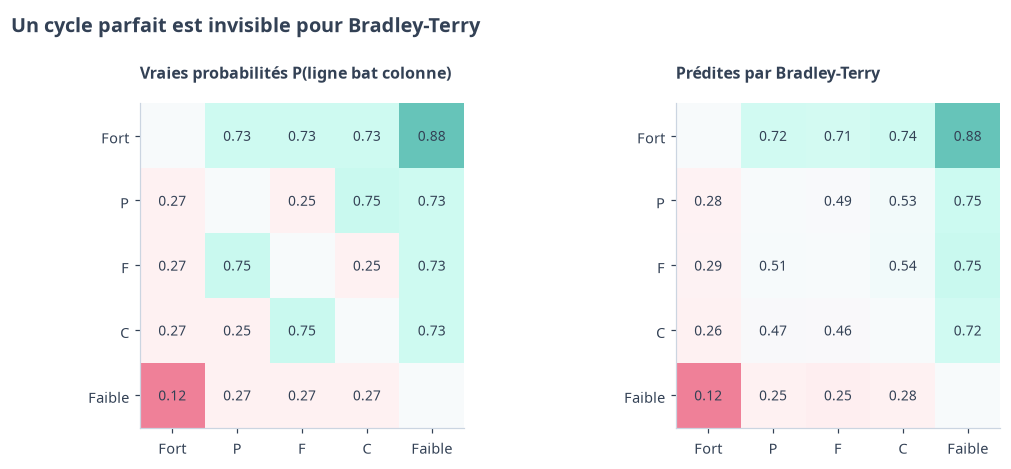

,Fort,P,F,C,Faible
score,1169.0,1008.0,1014.0,989.0,821.0


In [11]:
noms6 = ["Fort", "P", "F", "C", "Faible"]
P6 = np.full((5, 5), 0.5)
force = {"Fort": 1.0, "P": 0.0, "F": 0.0, "C": 0.0, "Faible": -1.0}
for i, a in enumerate(noms6):
    for j, b in enumerate(noms6):
        P6[i, j] = 1 / (1 + np.exp(-(force[a] - force[b])))
for a, b in [("P", "C"), ("C", "F"), ("F", "P")]:   # P bat C, C bat F, F bat P
    i, j = noms6.index(a), noms6.index(b)
    P6[i, j], P6[j, i] = 0.75, 0.25
m6 = ev.simulate_matches(P6, 5000, np.random.default_rng(2))
s6 = ev.bradley_terry(ev.win_matrix(m6, 5))
Ppred = 1 / (1 + np.exp(-(s6[:, None] - s6[None, :])))
fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
for ax, M, t in [(axes[0], P6, "Vraies probabilités P(ligne bat colonne)"), (axes[1], Ppred, "Prédites par Bradley-Terry")]:
    ax.imshow(M, cmap="aie_div", vmin=0, vmax=1)
    for i in range(5):
        for j in range(5):
            if i != j:
                ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=9)
    ax.set_xticks(range(5)); ax.set_xticklabels(noms6); ax.set_yticks(range(5)); ax.set_yticklabels(noms6)
    ax.set_title(t, fontsize=10.5); ax.grid(False)
finish(fig, "Un cycle parfait est invisible pour Bradley-Terry")
plt.show()
pd.Series(ev.bt_to_elo(s6), index=noms6, name="score").round(0).to_frame().T

Bradley-Terry attribue à P, F et C des scores presque identiques et prédit 50 % pour
leurs duels, alors que chaque duel est déséquilibré à 75/25. Le classement global reste
juste pour Fort et Faible, mais toute l'information du cycle est perdue. En pratique,
des cycles partiels apparaissent quand des modèles excellent dans des domaines différents
(code contre conversation, par exemple) : un classement unique masque ces spécialités,
d'où les classements par catégorie de prompts.

> **À retenir.** Un score unique ne peut pas représenter des préférences cycliques. Les
> classements par catégorie (code, maths, conversation...) et l'examen des résidus
> limitent ce problème.

## 7. Combien de comparaisons faut-il ? (section *Scalability bottlenecks*)

**Croissance quadratique.** Avec $n$ modèles, il y a $\binom n2 = n(n-1)/2$ paires. Le
livre cite LMSYS en janvier 2024 : 57 modèles, soit 1 596 paires, et 244 000
comparaisons, à peine 153 par paire en moyenne.

**Combien de matchs pour départager deux modèles ?** Pour détecter qu'un taux de
victoire $p$ diffère de 50 % (test bilatéral à 5 %, puissance 80 %), il faut environ
$$n \approx \left(\frac{1{,}96 \times 0{,}5 + 0{,}84\sqrt{p(1-p)}}{p - 0{,}5}\right)^2$$
matchs : l'effectif explose quand $p \to 0{,}5$.

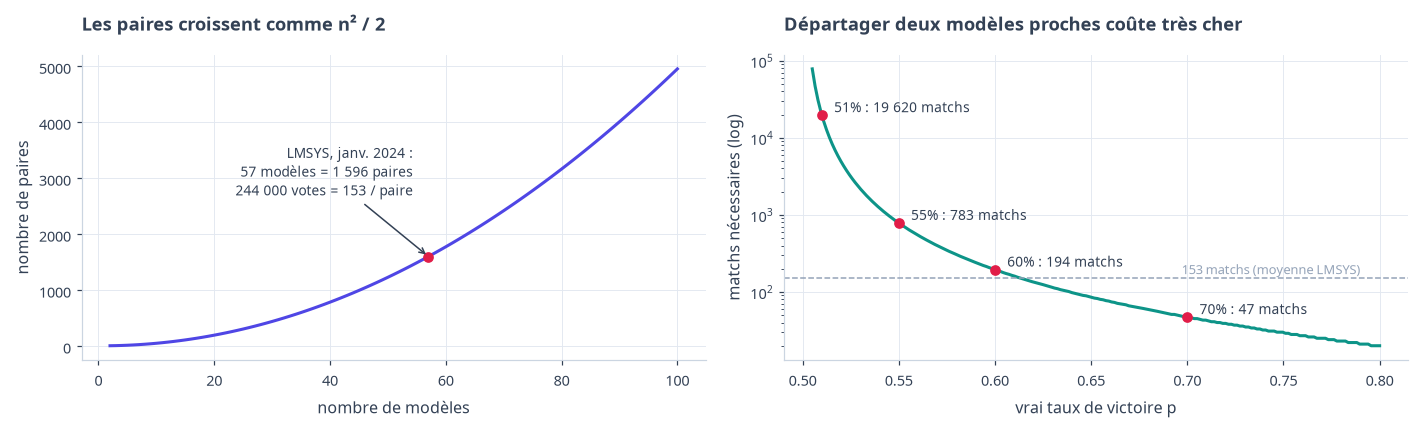

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
nm = np.arange(2, 101)
axes[0].plot(nm, nm * (nm - 1) / 2, color=INDIGO)
axes[0].scatter([57], [57 * 56 / 2], color=ROSE, zorder=3)
axes[0].annotate("LMSYS, janv. 2024 :\n57 modèles = 1 596 paires\n244 000 votes = 153 / paire", (57, 1596), (-10, 40),
                 textcoords="offset points", fontsize=9, ha="right", arrowprops=dict(arrowstyle="->", color=SLATE))
axes[0].set_xlabel("nombre de modèles"); axes[0].set_ylabel("nombre de paires")
axes[0].set_title("Les paires croissent comme n² / 2")
ps = np.linspace(0.505, 0.8, 200)
axes[1].plot(ps, [ev.matches_needed(p) for p in ps], color=TEAL)
for p in [0.51, 0.55, 0.6, 0.7]:
    n_ = ev.matches_needed(p)
    axes[1].scatter([p], [n_], color=ROSE, zorder=3)
    axes[1].annotate(f"{p:.0%} : {n_:,} matchs".replace(",", " "), (p, n_), (8, 2), textcoords="offset points", fontsize=9)
axes[1].axhline(153, color=GRAY, ls="--", lw=1)
axes[1].text(0.79, 170, "153 matchs (moyenne LMSYS)", ha="right", fontsize=8.5, color=GRAY)
axes[1].set_yscale("log"); axes[1].set_xlabel("vrai taux de victoire p"); axes[1].set_ylabel("matchs nécessaires (log)")
axes[1].set_title("Départager deux modèles proches coûte très cher")
finish(fig)
plt.show()

Avec 153 matchs, on ne distingue de façon fiable que des écarts de l'ordre de 60/40 ; un
51/49 demande près de 20 000 matchs. Heureusement, la **transitivité** (supposée)
permet de ne pas comparer toutes les paires directement, et un **appariement adaptatif**
concentre les matchs là où l'incertitude est la plus grande (le livre : arrêter de
comparer une paire dont l'issue est sûre).

**Simulation.** 20 modèles de forces tirées au hasard ; budget croissant de matchs ;
deux stratégies : paires tirées **uniformément**, ou paires **adaptatives** (par lots de
100, on réestime Bradley-Terry et l'on tire les paires avec une probabilité
proportionnelle à $p(1-p)$, maximale quand l'issue prédite est incertaine). Mesure : le
$\tau$ de Kendall entre classement estimé et vrai classement (1 = parfait).

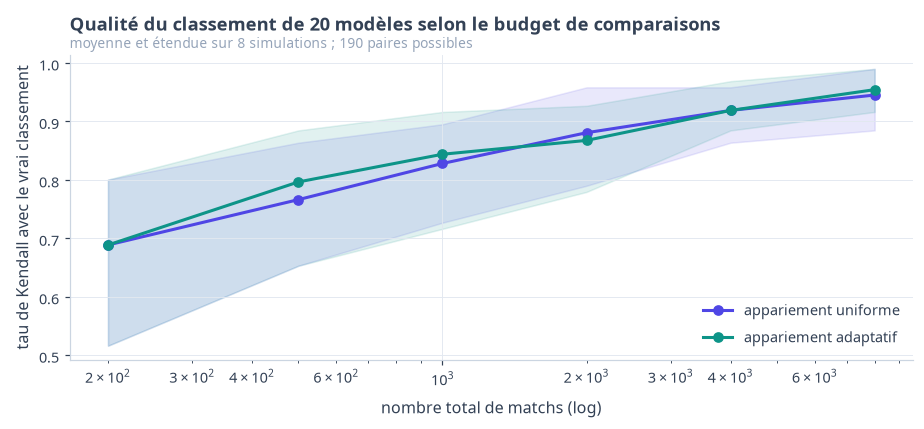

In [13]:
def simulation_budget(budgets, adaptatif, n_models=20, reps=8, lot=100):
    res = np.zeros((reps, len(budgets)))
    paires = list(combinations(range(n_models), 2))
    for r in range(reps):
        g = np.random.default_rng(100 + r)
        vraie = g.normal(1000, 120, n_models)
        Pm = ev.prob_matrix_from_elo(vraie)
        hist = []
        s = np.zeros(n_models)
        for bi, B in enumerate(budgets):
            while len(hist) < B:
                if adaptatif and len(hist) >= 2 * lot:
                    pp = np.array([1 / (1 + np.exp(-(s[a] - s[b]))) for a, b in paires])
                    w = pp * (1 - pp); w /= w.sum()
                    choix = [paires[k] for k in g.choice(len(paires), size=lot, p=w)]
                else:
                    choix = [paires[k] for k in g.integers(len(paires), size=lot)]
                for a, b in choix:
                    if g.random() < 0.5:
                        a, b = b, a
                    hist.append((a, b, float(g.random() < Pm[a, b])))
                s = ev.bradley_terry(ev.win_matrix(hist, n_models), prior=1.0, n_iter=300)
            res[r, bi] = kendalltau(s, vraie).statistic
    return res


budgets = [200, 500, 1000, 2000, 4000, 8000]
uni = simulation_budget(budgets, adaptatif=False)
ada = simulation_budget(budgets, adaptatif=True)
fig, ax = plt.subplots(figsize=(8.5, 4))
for res, c, nom in [(uni, INDIGO, "appariement uniforme"), (ada, TEAL, "appariement adaptatif")]:
    ax.plot(budgets, res.mean(0), "o-", color=c, label=nom)
    ax.fill_between(budgets, res.min(0), res.max(0), color=c, alpha=0.12)
ax.set_xscale("log"); ax.set_xlabel("nombre total de matchs (log)"); ax.set_ylabel("tau de Kendall avec le vrai classement")
ax.set_title("Qualité du classement de 20 modèles selon le budget de comparaisons")
subtitle(ax, "moyenne et étendue sur 8 simulations ; 190 paires possibles")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

La qualité du classement croît lentement avec le budget (rendements décroissants : il
faut multiplier les matchs pour départager les modèles proches). L'appariement adaptatif
concentre l'effort sur les paires voisines, celles qui déterminent l'ordre fin ; dans
cette simulation, son gain est faible et du même ordre que la variabilité entre
simulations. Il devient plus net quand les forces sont très dispersées (beaucoup de
paires à l'issue certaine, donc gaspillées par le tirage uniforme) ou quand on cherche
surtout à identifier le meilleur modèle : l'exercice 3.12 explore cette question.
Le livre signale enfin d'autres coûts du comparatif : chaque nouveau modèle doit être
comparé aux anciens (et peut modifier leur classement), et un modèle privé exige sa
propre arène.

> **À retenir.** Le nombre de paires croît en $n^2$ et départager deux modèles proches
> demande des milliers de matchs. La transitivité et l'appariement adaptatif réduisent le
> coût, sans le supprimer.

## 8. Du comparatif à l'absolu (section *From comparative performance to absolute performance*)

Savoir que B bat A ne dit pas si A ou B est **assez bon**. L'exemple du livre : A résout
70 % des tickets de support, B bat A dans 51 % des duels. Combien de tickets B
résout-il ? Modélisons : sur chaque ticket, A et B réussissent indépendamment avec
probabilités $p_A$ et $p_B$ ; si un seul réussit, il gagne le duel ; si les deux
réussissent ou échouent, le votant tranche sur d'autres critères (style, longueur...) et
préfère B avec probabilité $\beta$. Alors
$$W_B = p_B(1 - p_A) + \beta\,\big[p_A p_B + (1-p_A)(1-p_B)\big].$$
Avec $\beta = 1/2$ (pas de préférence de style), $W_B = \tfrac12 + \tfrac{p_B - p_A}2$ :
51 % de victoires valent 2 points de résolution. Mais si le style compte, tout change.

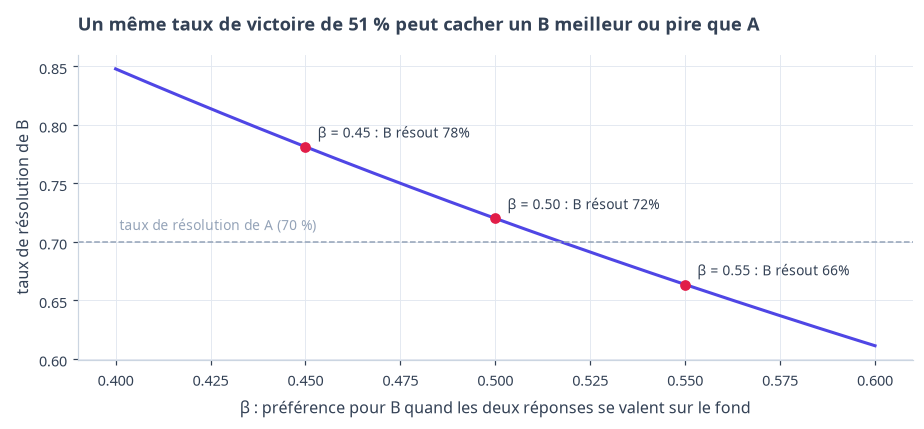

In [14]:
pA, WB = 0.70, 0.51
betas = np.linspace(0.40, 0.60, 201)
# W_B est affine en p_B : on résout W_B(p_B) = 0,51
pB = [(WB - b * (1 - pA)) / ((1 - pA) + b * pA - b * (1 - pA)) for b in betas]
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(betas, pB, color=INDIGO)
ax.axhline(pA, color=GRAY, ls="--", lw=1); ax.text(0.401, pA + 0.01, "taux de résolution de A (70 %)", fontsize=9, color=GRAY)
for b in [0.45, 0.5, 0.55]:
    y = (WB - b * (1 - pA)) / ((1 - pA) + b * pA - b * (1 - pA))
    ax.scatter([b], [y], color=ROSE, zorder=3)
    ax.annotate(f"β = {b:.2f} : B résout {y:.0%}", (b, y), (8, 6), textcoords="offset points", fontsize=9)
ax.set_xlabel("β : préférence pour B quand les deux réponses se valent sur le fond")
ax.set_ylabel("taux de résolution de B")
ax.set_title("Un même taux de victoire de 51 % peut cacher un B meilleur ou pire que A")
plt.tight_layout(); plt.show()

Selon la façon dont les votants départagent les réponses équivalentes, un taux de
victoire de 51 % correspond à un B qui résout nettement **plus** de tickets que A ou
même **moins** (si B gagne surtout par son style). D'où le constat du livre : 1 point de
taux de victoire peut valoir beaucoup dans une application et presque rien dans une
autre, et l'analyse coût-bénéfice (B coûte-t-il deux fois plus cher ?) exige une mesure
**absolue** de la qualité sur sa propre tâche.

**L'avenir du comparatif** (section *The Future of Comparative Evaluation*). Malgré ces
limites, le livre lui voit de beaux jours : comparer reste possible quand noter devient
impossible (modèles meilleurs que les annotateurs, comme le rapporte l'article de
Llama 2), le comparatif mesure directement la préférence humaine, ne sature pas tant
que de nouveaux modèles arrivent, et se triche difficilement (pas de données de référence
sur lesquelles s'entraîner). Il complète les benchmarks hors ligne et les tests A/B en
ligne.

> **À retenir.** Un taux de victoire est une mesure relative : il ne dit ni si un modèle
> est suffisant, ni combien vaut le gain. Il faut le compléter par une évaluation absolue
> sur sa tâche, et par une analyse du coût.

## Synthèse

- **Comparatif** : des duels plutôt que des notes ; adapté aux qualités subjectives ; à
  réserver aux questions de préférence et à des votants compétents.
- **Bradley-Terry** : $P(i \succ j) = \sigma(s_i - s_j)$ ; estimation par maximum de
  vraisemblance (MM), indépendante de l'ordre, avec intervalles bootstrap.
- **Elo** : même modèle, mise à jour en ligne = gradient stochastique à pas $K$ ; sensible
  à l'ordre des matchs, d'où l'abandon par LMSYS.
- **Limites** : intransitivité (cycles, y compris dans la table 3-6), coût quadratique et
  milliers de matchs pour départager des modèles proches, contrôle qualité des votes,
  passage difficile du relatif à l'absolu.

**Liens.** Le cours 3 a montré comment produire des préférences avec un juge IA (et ses
biais, qui contaminent un classement) ; le chapitre 2 a utilisé les mêmes données de
préférence pour l'alignement (RLHF, le modèle de récompense est un Bradley-Terry) ; le
chapitre 4 verra comment combiner benchmarks publics, évaluation comparative et
évaluation sur ses propres données pour choisir un modèle.